In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

sz = np.array([[1, 0], [0, -1]])
sx = np.array([[0, 1], [1, 0]])
sy = np.array([[0, -1j], [1j, 0]])
hbar = 1e-34
B = 0.1 # 100 mT
muB = 9.27e-24

H = muB * B * sz # g = 2
psi0 = np.array([[1], [1]])/np.sqrt(2) # initial state is the |+> state
Nt = 500
tt = np.linspace(0, 1e-9, Nt + 1)
psipsi = np.zeros((2,Nt + 1), dtype = complex)
azaz = np.zeros(Nt + 1)
ayay = np.zeros(Nt + 1)
axax = np.zeros(Nt + 1)
for i in range(Nt + 1):
  t = tt[i]
  psi = sp.linalg.expm(-1j * H / hbar * t) @ psi0 # |psi(t)> = exp(-i*H*t/hbar) |psi0>
  psipsi[:, i] = psi.T
  axax[i]  = (psi.T.conj() @ sx @ psi)[0, 0]
  ayay[i]  = (psi.T.conj() @ sy @ psi)[0, 0]
  azaz[i]  = (psi.T.conj() @ sz @ psi)[0, 0]

/tmp/ipython-input-1645680532.py:24: ComplexWarning: Casting complex values to real discards the imaginary part
  axax[i]  = (psi.T.conj() @ sx @ psi)[0, 0]
/tmp/ipython-input-1645680532.py:25: ComplexWarning: Casting complex values to real discards the imaginary part
  ayay[i]  = (psi.T.conj() @ sy @ psi)[0, 0]
/tmp/ipython-input-1645680532.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  azaz[i]  = (psi.T.conj() @ sz @ psi)[0, 0]


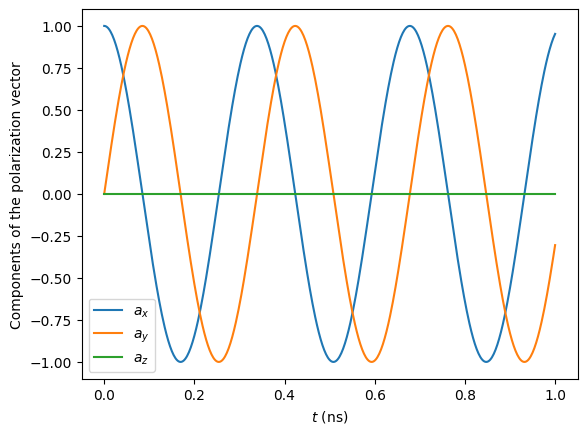

In [2]:
plt.plot(tt*1e9, axax)
plt.plot(tt*1e9, ayay)
plt.plot(tt*1e9, azaz)
plt.legend(['$a_x$', '$a_y$', '$a_z$'])
plt.xlabel('$t$ (ns)')
plt.ylabel('Components of the polarization vector')
plt.show()